<a href="https://colab.research.google.com/github/alottamyles/Hystrix/blob/2026fall_myles/BUS4_118S_Order_Status_Agent_UPDATED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup Models

In [ ]:
print("Hello! My Order Status Agent project is ready.")


Hello! My Order Status Agent project is ready.


In [ ]:
%pip install -q -U langchain-google-genai

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

print("Gemini library imported successfully!")

Gemini library imported successfully!


In [ ]:
import os
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI

# Get API key securely
os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")

# Launch Gemini
model = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite",
)

print("Gemini model launched successfully!")

Gemini model launched successfully!


In [ ]:
response = model.invoke(
    "Hello! Introduce yourself as a customer service assistant in one sentence."
)

print(response.content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': "Hello, I'm your dedicated customer service assistant, here to help answer your questions and resolve any issues you may have quickly and efficiently.", 'extras': {'signature': 'EmAKXgFpFH0TZ9Qz+hRCfII1hYg5uzClJsCs7Dbf9P/aeTEqDmZIV5PKuad5OM37Zvp9bRK26sSthrBQTRQH3scZVYeKMezDyMvKf+Hwl7DRqSpy7XNG/lqUVPeBw0arJIk='}}]


## 04.03. Setup tools for custom Agent

In [ ]:
import pandas as pd

# Sample customer orders (fake data)
orders = {
    "Order ID": [
        "ORD-8276", "ORD-6948","ORD-7311","ORD-4633","ORD-2050"
    ],
    "Product Ordered": [
        "SpectraBook S", "OmegaPro G17",
        "NanoEdge Flex", "OmegaPro G17",
        "GammaAir X"
    ],
    "Quantity Ordered": [3, 3, 2, 2, 2],
    "Order Status": [
        "Processing", "Shipped", "Delivered", "Processing", "Delivered"
    ],
    "Estimated Delivery": [
        "2026-10-25", "2026-10-23",
        "2026-10-18", "2026-10-24",
        "2026-10-28"
    ]
}

product_orders_df = pd.DataFrame(orders)
print(product_orders_df)

   Order ID Product Ordered  Quantity Ordered Order Status Estimated Delivery
0  ORD-8276   SpectraBook S                 3   Processing         2026-10-25
1  ORD-6948    OmegaPro G17                 3      Shipped         2026-10-23
2  ORD-7311   NanoEdge Flex                 2    Delivered         2026-10-18
3  ORD-4633    OmegaPro G17                 2   Processing         2026-10-24
4  ORD-2050      GammaAir X                 2    Delivered         2026-10-28


In [ ]:
from langchain_core.tools import tool

@tool
def get_order_details(order_id:str) -> str :
    """
    Look up a customer's order by its order ID. Return the product, quantity, order status, and estimated delivery date
    """

    #Find the requested order
    match = product_orders_df[
        product_orders_df["Order ID"].str.upper()
        == order_id.strip().upper()
    ]

    # Handle invalid order number
    if match.empty:
        return {
            "error": "Order not found",
            "order_id": order_id
        }

    # Return matching order details
    return match.iloc[0].to_dict()

# Test valid order
print(get_order_details.invoke({
    "order_id": "ORD-6948"
}))

# Test invalid order
print(get_order_details.invoke({
    "order_id": "ORD-9999"
}))

{'Order ID': 'ORD-6948', 'Product Ordered': 'OmegaPro G17', 'Quantity Ordered': 3, 'Order Status': 'Shipped', 'Estimated Delivery': '2026-10-23'}
{'error': 'Order not found', 'order_id': 'ORD-9999'}


## 04.04. Setup the Custom Orders Agent

Order Status Agent initialized successfully!


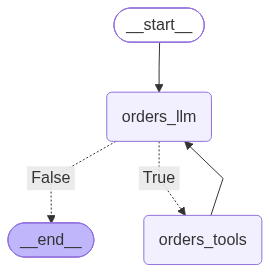

In [35]:
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from IPython.display import Image
import json

#An Agent State class that keep state of the agent while it answers a query
class OrdersAgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

#-----------------------------------------------------------------------------
#An agent class that manages all agentic interactions
class OrdersAgent:

    #Setup the agent graph, tools and memory
    def __init__(self, model, tools, system_prompt, debug):

        self.system_prompt=system_prompt
        self.debug=debug

        #Setup the graph for the agent manually
        agent_graph=StateGraph(OrdersAgentState)
        agent_graph.add_node("orders_llm",self.call_llm)
        agent_graph.add_node("orders_tools",self.call_tools)
        agent_graph.add_conditional_edges(
            "orders_llm",
            self.is_tool_call,
            {True: "orders_tools", False: END }
        )
        agent_graph.add_edge("orders_tools","orders_llm")
        #Set where there graph starts
        agent_graph.set_entry_point("orders_llm")

        #Add chat memory
        self.memory=MemorySaver()
        #compile the graph
        self.agent_graph = agent_graph.compile(checkpointer=self.memory)

        #Setup tools
        self.tools = { tool.name : tool for tool in tools }
        if self.debug:
            print("\nTools loaded :", self.tools)

        #attach tools to model
        self.model=model.bind_tools(tools)


    #Call the LLM with the messages to get next action/result
    def call_llm(self, state:OrdersAgentState):

        messages=state["messages"]

        #If system prompt exists, add to messages in the front
        if self.system_prompt:
            messages = [SystemMessage(content=self.system_prompt)] + messages

        #invoke the model with the message history
        result = self.model.invoke(messages)
        if self.debug:
            print(f"\nLLM Returned : {result}")
        #Return the LLM output
        return { "messages":[result] }


    #Check if the next action is a tool call.
    def is_tool_call(self, state:OrdersAgentState):
        last_message = state["messages"][-1]
        #print("Last result from LLM : ", last_message)
        #If tool action is requested
        if len(last_message.tool_calls) > 0 :
            return True
        else:
            return False

    #Execute the tool requested with the given parameters
    def call_tools(self, state:OrdersAgentState):
        #Get last message
        tool_calls = state["messages"][-1].tool_calls
        results=[]

        #Multiple tool calls may be requested. Execute one by one
        for tool in tool_calls:
            #Handle tool missing error
            if not tool["name"] in self.tools:
                print(f"Unknown tool name {tool}")
                result = "Invalid tool found. Please retry"
            else:
                #Call the tool and collect results
                result=self.tools[tool["name"]].invoke(tool["args"])

            #append results to the list of tool results
            results.append(ToolMessage(tool_call_id=tool['id'],
                                       name=tool['name'],
                                       content=str(result)))

            if self.debug:
                print(f"\nTools returned {results}")
        return {"messages": results}

#-----------------------------------------------------------------------------
#Setup the custom agent

#Note that this is a string, since the model init only accepts a string.
system_prompt = """
You are a friendly and professional customer service assistant for a fictional laptop store. Your responsibility is to help customers check their order status.

Instructions:
1. Use get_order_details to look up customer orders
2. Provide order status and estimated delivery date
3. Ask for order ID if the customer hasn't provided one
4. Remember previously mentioned order IDs during the conversation
5. Politely explain when an order cannot be found
6. Respond professionally to greetings and small talk.

IMPORTANT:
- Do not make up order details or delivery dates
- Only provide information regarding the requested order
- Do not claim to access real shipping systems
- Keep responses clear and concise
"""

#Create Order Status agent
orders_agent = OrdersAgent(model,
                           [get_order_details],
                           system_prompt,
                           debug=False)

print("Order Status Agent initialized successfully!")

# Visualize agent graph
Image(orders_agent.agent_graph.get_graph().draw_mermaid_png())


## 04.05 Setup and execute the Orders Chatbot

In [40]:

import uuid
from langchain_core.messages import HumanMessage

# Customer conversation simulation
user_inputs = [
    "Hi! Can you check the status of order ORD-6948?",
    "When is my order expected to arrive?",
    "What laptop did I order?",
    "How many laptops did I order?",
    "Can you check order ORD-9999?",
    "Thank you!"
]

# Create new conversation thread
config = {
    "configurable": {
        "thread_id": str(uuid.uuid4())
    }
}

# Send each message to the chatbot
for user_input in user_inputs:

    print("\n" + "-" * 50)
    print("CUSTOMER:", user_input)

    user_message = {
        "messages": [HumanMessage(content=user_input)]
    }

    # Get agent's response
    response = orders_agent.agent_graph.invoke(
        user_message,
        config=config
    )

    # Extract and display the agent's answer
    final_message = response["messages"][-1]

    if isinstance(final_message.content, str):
        answer = final_message.content
    else:
        answer = " ".join(
            block.get("text", "")
            for block in final_message.content
            if isinstance(block, dict)
            and block.get("type") == "text"
        )

    print("AGENT:", answer, flush=True)



--------------------------------------------------
CUSTOMER: Hi! Can you check the status of order ORD-6948?
AGENT: Hello! I'd be happy to help you with that.

Your order for 3 units of the OmegaPro G17 (Order ID: ORD-6948) has been shipped and is estimated to be delivered on October 23, 2026. 

Let me know if there is anything else I can help you with!

--------------------------------------------------
CUSTOMER: When is my order expected to arrive?
AGENT: Your order (ORD-6948) is estimated to arrive on October 23, 2026. 

Let me know if you have any other questions!

--------------------------------------------------
CUSTOMER: What laptop did I order?
AGENT: You ordered 3 units of the OmegaPro G17 laptop. 

Is there anything else I can help you with today?

--------------------------------------------------
CUSTOMER: How many laptops did I order?
AGENT: You ordered 3 laptops (the OmegaPro G17). 

Let me know if you need help with anything else!

-------------------------------------